# Gravedad de siniestros viales en CABA con una red neuronal en Keras
## Notebook 4: de un ensamble de `MLPClassifier` a una red con embeddings, focal loss y un enfoque ordinal

Este notebook continúa el **Notebook 2** (`02_modelo_clasificacion_gravedad.ipynb`, que no se modifica). Allí el mejor F1 macro en test fue **0,48** (Random Forest optimizado) y el ensamble de redes de scikit-learn quedó en 0,47, con un recall de MORTAL bajo (0,18 a 0,36).

**Qué cambia acá:**

1. **Validación honesta en el tiempo.** El Notebook 2 partía al azar. Acá se entrena con 2019 a 2023, se ajusta (early stopping, umbrales) con 2024 y se evalúa una sola vez en **2025**, como pasaría en producción.
2. **Variables nuevas:** coordenadas, **tasa histórica de gravedad en el entorno** (celdas H3 vecinas, calculada fuera de pliegue para no filtrar el target), hora y mes en **seno/coseno**, y agregados de víctimas (edades, sexo, modos), **sin usar la fecha de fallecimiento ni la gravedad de la víctima**.
3. **Red en Keras:** embeddings para las categóricas, BatchNorm, Dropout, AdamW, **focal loss** y early stopping guiado por el F1 macro de validación.
4. **Enfoque ordinal en dos etapas:** primero ¿es al menos GRAVE?, después ¿es MORTAL dado que es al menos GRAVE?
5. **Comparación justa** con LightGBM y Random Forest en el mismo split, midiendo **F1 macro** y **recall de MORTAL**.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h3
import keras
from keras import layers
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold
from sklearn.decomposition import PCA
from sklearn.metrics import (f1_score, recall_score, precision_score, classification_report,
                             ConfusionMatrixDisplay, confusion_matrix)

print("keras", keras.__version__, "| backend", keras.backend.backend(), "| lightgbm", lgb.__version__)

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
CLASES = ["LEVE", "GRAVE", "MORTAL"]
COLORES = {"LEVE": "#8FB3C9", "GRAVE": "#E0A458", "MORTAL": "#C46A5E"}
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 110})
CARPETA_GRAFICOS = "graficos"
os.makedirs(CARPETA_GRAFICOS, exist_ok=True)

I0000 00:00:1795549012.960243   23072 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795549014.111771   23072 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


keras 3.15.1 | backend tensorflow | lightgbm 4.7.0


## 1. Datos
Se parte de las tablas ya limpias que genera el Notebook 2 (`hechos_limpio.csv` y `victimas_limpio.csv`, una carpeta arriba).

In [2]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA = "/content/drive/MyDrive/datos/"
except ImportError:
    RUTA = "../"

hechos = pd.read_csv(RUTA + "hechos_limpio.csv", sep=";", low_memory=False,
                     parse_dates=["fecha_siniestro"])
victimas = pd.read_csv(RUTA + "victimas_limpio.csv", sep=";", low_memory=False)
print("hechos:", hechos.shape, "| víctimas:", victimas.shape)
hechos["gravedad"].value_counts().to_frame("siniestros").assign(
    pct=lambda d: (d["siniestros"] / d["siniestros"].sum() * 100).round(2))

hechos: (65818, 28) | víctimas: (75193, 11)


,siniestros,pct
gravedad,,
LEVE,62143,94.42
GRAVE,2986,4.54
MORTAL,689,1.05


### 1.1 Cuidado con las fugas de información
Antes de sumar variables de víctimas conviene mirar cómo se registran. Las tablas mezclan dos fuentes: los hechos con lesiones (`LC-`) y los homicidios culposos (`HC-`). Algunas columnas **delatan la fuente**, y por lo tanto la gravedad, sin aportar nada causal:

In [3]:
print(pd.crosstab(hechos["id_siniestro"].str[:2], hechos["gravedad"]), "\n")
print(pd.crosstab(victimas["rol_victima"], victimas["gravedad_victima"]))

gravedad      GRAVE   LEVE  MORTAL
id_siniestro                      
HC                0      0     689
LC             2986  62143       0 

gravedad_victima  GRAVE   LEVE  MORTAL
rol_victima                           
CICLISTA            235   5992      54
CONDUCTOR             0      0     307
PASAJERO              0      0      64
PEATON              802   7328     275
SIN DATOS          2145  57988       3


* El prefijo del id es la gravedad (HC = MORTAL), así que nunca se usa.
* `rol_victima` = CONDUCTOR o PASAJERO aparece **solo** en mortales: es un campo que llena la fuente de homicidios. Se descarta.
* `gravedad_victima`, `fallecio` y `fecha_fallecimiento_victima` son el target por otra vía. Se descartan.

Sí se usan: cantidad de víctimas, edades, sexo y modo de desplazamiento de cada víctima, que se conocen al momento del hecho.

## 2. Variables
### 2.1 Agregados de víctimas por siniestro

In [4]:
v = victimas.copy()
v["edad_obs"] = v["edad_victima"].where(~v["edad_imputada"].astype(bool))
v["masc"] = np.where(v["sexo_victima"] == "SIN DATOS", np.nan, (v["sexo_victima"] == "MASCULINO").astype(float))
for modo in ["PEATON", "MOTO", "BICICLETA", "AUTO"]:
    v[f"v_{modo.lower()}"] = (v["modo_desplazamiento_victima"] == modo).astype(int)
v["v_mayor_65"] = (v["edad_obs"] >= 65).astype(int)
v["v_menor_18"] = (v["edad_obs"] < 18).astype(int)

agg_victimas = v.groupby("id_siniestro").agg(
    n_victimas=("id_siniestro", "size"),
    edad_media=("edad_obs", "mean"),
    edad_max=("edad_obs", "max"),
    edad_min=("edad_obs", "min"),
    share_masc=("masc", "mean"),
    v_peaton=("v_peaton", "sum"), v_moto=("v_moto", "sum"),
    v_bicicleta=("v_bicicleta", "sum"), v_auto=("v_auto", "sum"),
    v_mayor_65=("v_mayor_65", "sum"), v_menor_18=("v_menor_18", "sum"),
).reset_index()

datos = hechos.merge(agg_victimas, on="id_siniestro", how="left")
datos.filter(like="v_").describe().T[["mean", "max"]].round(2)

,mean,max
v_peaton,0.13,8.0
v_moto,0.35,7.0
v_bicicleta,0.10,4.0
v_auto,0.14,8.0
v_mayor_65,0.06,4.0
v_menor_18,0.03,13.0


### 2.2 Tiempo: hora y mes en el círculo
La hora 23 está al lado de la 0. Con seno y coseno la red ve esa cercanía; con un número de 0 a 23 no.

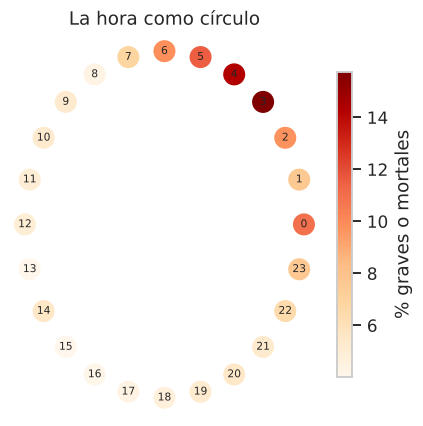

In [5]:
datos["hora"] = datos["hora"].fillna(datos["hora"].median())
datos["hora_sin"] = np.sin(2 * np.pi * datos["hora"] / 24)
datos["hora_cos"] = np.cos(2 * np.pi * datos["hora"] / 24)
datos["mes_sin"] = np.sin(2 * np.pi * (datos["mes"] - 1) / 12)
datos["mes_cos"] = np.cos(2 * np.pi * (datos["mes"] - 1) / 12)
datos["finde"] = (datos["dia_semana"] >= 5).astype(int)
datos["noche"] = ((datos["hora"] >= 22) | (datos["hora"] <= 5)).astype(int)

fig, ax = plt.subplots(figsize=(4.5, 4.5))
tasa_hora = datos.groupby("hora")["gravedad"].apply(lambda s: s.isin(["GRAVE", "MORTAL"]).mean())
sc = ax.scatter(np.cos(2 * np.pi * tasa_hora.index / 24), np.sin(2 * np.pi * tasa_hora.index / 24),
                c=tasa_hora.values * 100, s=180, cmap="OrRd")
for h_, x_, y_ in zip(tasa_hora.index, np.cos(2 * np.pi * tasa_hora.index / 24), np.sin(2 * np.pi * tasa_hora.index / 24)):
    ax.annotate(int(h_), (x_, y_), ha="center", va="center", fontsize=7)
plt.colorbar(sc, label="% graves o mortales", shrink=0.8)
ax.set_title("La hora como círculo")
ax.set_axis_off()
plt.savefig(f"{CARPETA_GRAFICOS}/hora_circular.png", bbox_inches="tight")
plt.show()

### 2.3 Split temporal
Se corta antes de construir la tasa espacial, porque esa variable usa el target y tiene que calcularse solo con el pasado.

In [6]:
datos["anio"] = datos["fecha_siniestro"].dt.year
datos["y"] = datos["gravedad"].map({c: i for i, c in enumerate(CLASES)})

es_train = datos["anio"] <= 2023
es_valid = datos["anio"] == 2024
es_test = datos["anio"] == 2025

pd.crosstab(np.select([es_train, es_valid, es_test], ["train 2019-23", "valid 2024", "test 2025"], default=""),
            datos["gravedad"], normalize="index").mul(100).round(2)[CLASES]

gravedad,LEVE,GRAVE,MORTAL
row_0,,,
test 2025,93.39,5.85,0.77
train 2019-23,94.80,4.08,1.12
valid 2024,94.00,4.96,1.04


### 2.4 Coordenadas y tasa histórica de gravedad en el entorno (fuera de pliegue)
Cada siniestro se ubica en una celda hexagonal **H3 de resolución 8** (~0,7 km²). Para cada celda se suma lo ocurrido en ella y en sus 6 vecinas y se calcula una tasa suavizada (bayesiana) de siniestros graves o mortales y de mortales:

$$\text{tasa} = \frac{\text{casos en el entorno} + m \cdot \text{tasa global}}{\text{siniestros en el entorno} + m}$$

Para no filtrar el target, en **train** la tasa de cada fila se calcula con los **otros 5 pliegues** (out-of-fold). Validación y test usan la tasa de todo train, es decir, solo el pasado.

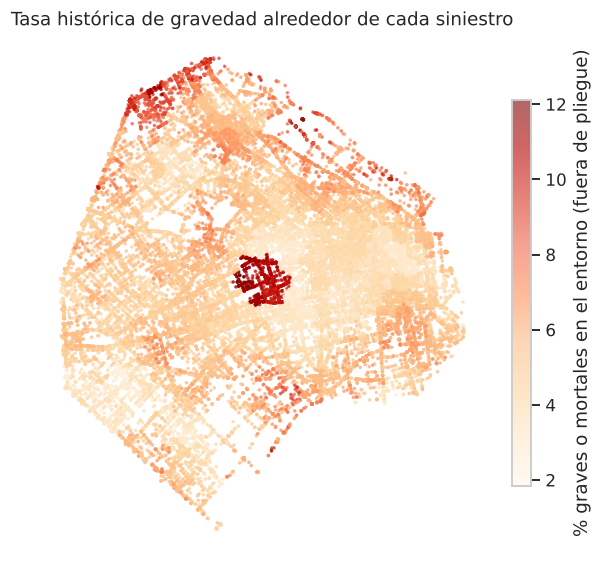

In [7]:
centro_comuna = datos[es_train].groupby("comuna")[["latitud_siniestro", "longitud_siniestro"]].median()
datos["coord_faltante"] = datos["latitud_siniestro"].isna().astype(int)
for col in ["latitud_siniestro", "longitud_siniestro"]:
    datos[col] = datos[col].fillna(datos["comuna"].map(centro_comuna[col]))
    datos[col] = datos[col].fillna(datos.loc[es_train, col].median())

datos["h3"] = [h3.latlng_to_cell(la, lo, 8) for la, lo in zip(datos["latitud_siniestro"], datos["longitud_siniestro"])]
datos["grave_o_mortal"] = (datos["y"] >= 1).astype(int)
datos["mortal"] = (datos["y"] == 2).astype(int)
vecinas = {c: h3.grid_disk(c, 1) for c in datos["h3"].unique()}
M = 30  # fuerza del suavizado: equivale a 30 siniestros "promedio"


def tasa_entorno(fuente, destino):
    """Tasas suavizadas por entorno H3 usando solo las filas de `fuente`."""
    conteo = fuente.groupby("h3").agg(n=("y", "size"), gm=("grave_o_mortal", "sum"), m=("mortal", "sum"))
    p_gm, p_m = fuente["grave_o_mortal"].mean(), fuente["mortal"].mean()
    filas = []
    for celda in destino["h3"].unique():
        s = conteo.reindex(vecinas[celda]).fillna(0).sum()
        filas.append((celda, s["n"], (s["gm"] + M * p_gm) / (s["n"] + M), (s["m"] + M * p_m) / (s["n"] + M)))
    tabla = pd.DataFrame(filas, columns=["h3", "n_entorno", "tasa_gm_entorno", "tasa_mortal_entorno"]).set_index("h3")
    return destino[["h3"]].join(tabla, on="h3").drop(columns="h3")


cols_entorno = ["n_entorno", "tasa_gm_entorno", "tasa_mortal_entorno"]
entorno = pd.DataFrame(index=datos.index, columns=cols_entorno, dtype=float)
idx_train = datos.index[es_train]
for dentro, fuera in KFold(5, shuffle=True, random_state=SEMILLA).split(idx_train):
    entorno.loc[idx_train[fuera]] = tasa_entorno(datos.loc[idx_train[dentro]], datos.loc[idx_train[fuera]]).values
entorno.loc[~es_train] = tasa_entorno(datos[es_train], datos[~es_train]).values
entorno["n_entorno"] = np.log1p(entorno["n_entorno"])
datos[cols_entorno] = entorno.astype(float)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
sc = ax.scatter(datos.loc[es_train, "longitud_siniestro"], datos.loc[es_train, "latitud_siniestro"],
                c=datos.loc[es_train, "tasa_gm_entorno"] * 100, s=2, cmap="OrRd", alpha=0.6)
plt.colorbar(sc, label="% graves o mortales en el entorno (fuera de pliegue)", shrink=0.7)
ax.set_title("Tasa histórica de gravedad alrededor de cada siniestro")
ax.set_aspect(1 / np.cos(np.radians(-34.6)))
ax.set_axis_off()
plt.savefig(f"{CARPETA_GRAFICOS}/mapa_tasa_entorno.png", bbox_inches="tight")
plt.show()

### 2.5 Matriz final
Las categóricas se codifican como enteros (para los embeddings de la red y las categóricas nativas de LightGBM). Las categorías con menos de 30 casos en train se agrupan en `OTRA`, y lo que no aparece en train también.

In [8]:
CATEGORICAS = ["tipo_de_via_siniestro", "modo_desplazamiento_victima", "contraparte_siniestro",
               "participantes_siniestro", "comuna", "dia_semana"]
NUMERICAS = ["hora_sin", "hora_cos", "mes_sin", "mes_cos", "finde", "noche",
             "latitud_siniestro", "longitud_siniestro", "coord_faltante",
             "n_entorno", "tasa_gm_entorno", "tasa_mortal_entorno",
             "n_victimas", "edad_media", "edad_max", "edad_min", "share_masc",
             "v_peaton", "v_moto", "v_bicicleta", "v_auto", "v_mayor_65", "v_menor_18"]

vocab = {}
for col in CATEGORICAS:
    datos[col] = datos[col].astype(str)
    frec = datos.loc[es_train, col].value_counts()
    vocab[col] = ["OTRA"] + sorted(frec[frec >= 30].index)
    mapa = {c: i for i, c in enumerate(vocab[col])}
    datos[col + "_id"] = datos[col].map(mapa).fillna(0).astype(int)

# faltantes numéricos: mediana de train + indicador de edad desconocida
datos["edad_desconocida"] = datos["edad_media"].isna().astype(int)
NUMERICAS.append("edad_desconocida")
for col in NUMERICAS:
    datos[col] = datos[col].fillna(datos.loc[es_train, col].median())

CAT_IDS = [c + "_id" for c in CATEGORICAS]
y_tr, y_va, y_te = datos.loc[es_train, "y"].values, datos.loc[es_valid, "y"].values, datos.loc[es_test, "y"].values
print({c: len(vocab[c]) for c in CATEGORICAS})
print("numéricas:", len(NUMERICAS), "| train", es_train.sum(), "| valid", es_valid.sum(), "| test", es_test.sum())

{'tipo_de_via_siniestro': 5, 'modo_desplazamiento_victima': 12, 'contraparte_siniestro': 12, 'participantes_siniestro': 74, 'comuna': 16, 'dia_semana': 8}
numéricas: 24 | train 43497 | valid 10569 | test 11752


### 2.6 Herramientas de evaluación comunes
Todos los modelos devuelven probabilidades para las tres clases. Como el F1 macro premia acertar las clases raras, después se **reescalan** las probabilidades de GRAVE y MORTAL con pesos elegidos en **validación 2024** (nunca en test) y se predice la clase con mayor probabilidad reescalada.

In [9]:
GRILLA_PESOS = np.exp(np.linspace(np.log(0.25), np.log(12), 30))


def ajustar_pesos(prob, y):
    mejor = (-1, (1.0, 1.0))
    for wg in GRILLA_PESOS:
        for wm in GRILLA_PESOS:
            pred = (prob * np.array([1, wg, wm])).argmax(1)
            f1 = f1_score(y, pred, average="macro")
            if f1 > mejor[0]:
                mejor = (f1, (wg, wm))
    return np.array([1, *mejor[1]])


def metricas(nombre, prob_va, prob_te):
    w = ajustar_pesos(prob_va, y_va)
    pred = (prob_te * w).argmax(1)
    return {"Modelo": nombre,
            "F1 macro valid": f1_score(y_va, (prob_va * w).argmax(1), average="macro"),
            "F1 macro test": f1_score(y_te, pred, average="macro"),
            "Recall GRAVE": recall_score(y_te, pred, labels=[1], average=None)[0],
            "Recall MORTAL": recall_score(y_te, pred, labels=[2], average=None)[0],
            "Precision MORTAL": precision_score(y_te, pred, labels=[2], average=None, zero_division=0)[0],
            "pesos (G, M)": f"{w[1]:.1f}, {w[2]:.1f}"}, pred


resultados, predicciones, probabilidades = [], {}, {}


def registrar(nombre, prob_va, prob_te):
    fila, pred = metricas(nombre, prob_va, prob_te)
    resultados.append(fila)
    predicciones[nombre], probabilidades[nombre] = pred, (prob_va, prob_te)
    return pd.DataFrame([fila]).round(3)

## 3. Puntos de referencia con árboles
### 3.1 Random Forest con las variables del Notebook 2
Mismo modelo y mismas variables que el Notebook 2, pero con el split temporal. Separa cuánto mejora por **variables** y cuánto por **modelo**.

In [10]:
VARS_NB2 = ["hora", "dia_semana", "mes", "n_victimas", "edad_media"]
CATS_NB2 = ["tipo_de_via_siniestro", "modo_desplazamiento_victima", "contraparte_siniestro", "comuna"]
X_nb2 = pd.get_dummies(datos[VARS_NB2 + CATS_NB2], columns=CATS_NB2, dtype=float)
rf_nb2 = RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_features="sqrt",
                                class_weight="balanced_subsample", n_jobs=-1, random_state=SEMILLA)
rf_nb2.fit(X_nb2[es_train], y_tr)
registrar("RF · variables del Notebook 2", rf_nb2.predict_proba(X_nb2[es_valid]), rf_nb2.predict_proba(X_nb2[es_test]))

,Modelo,F1 macro valid,F1 macro test,Recall GRAVE,Recall MORTAL,Precision MORTAL,"pesos (G, M)"
0,RF · variables del Notebook 2,0.428,0.4,0.137,0.056,0.111,"0.8, 0.2"


### 3.2 Random Forest con las variables nuevas

In [11]:
X_oh = pd.get_dummies(datos[NUMERICAS + CATEGORICAS], columns=CATEGORICAS, dtype=float)
rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_features="sqrt",
                            class_weight="balanced_subsample", n_jobs=-1, random_state=SEMILLA)
rf.fit(X_oh[es_train], y_tr)
registrar("Random Forest", rf.predict_proba(X_oh[es_valid]), rf.predict_proba(X_oh[es_test]))

,Modelo,F1 macro valid,F1 macro test,Recall GRAVE,Recall MORTAL,Precision MORTAL,"pesos (G, M)"
0,Random Forest,0.457,0.438,0.272,0.089,0.136,"1.1, 0.5"


### 3.3 LightGBM
Usa las categóricas de forma nativa y frena con early stopping sobre la log-loss de 2024.

In [12]:
X_lgb = datos[NUMERICAS + CAT_IDS].copy()
for c in CAT_IDS:
    X_lgb[c] = X_lgb[c].astype("category")
lgbm = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.02, num_leaves=31, min_child_samples=40,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
                          class_weight="balanced", random_state=SEMILLA, verbose=-1)
lgbm.fit(X_lgb[es_train], y_tr, eval_set=[(X_lgb[es_valid], y_va)],
         callbacks=[lgb.early_stopping(100, verbose=False)])
print("árboles usados:", lgbm.best_iteration_)
registrar("LightGBM", lgbm.predict_proba(X_lgb[es_valid]), lgbm.predict_proba(X_lgb[es_test]))

/usr/local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


árboles usados: 2000


,Modelo,F1 macro valid,F1 macro test,Recall GRAVE,Recall MORTAL,Precision MORTAL,"pesos (G, M)"
0,LightGBM,0.447,0.434,0.178,0.167,0.134,"0.9, 0.6"


## 4. La red en Keras
### 4.1 Arquitectura

```
 6 categóricas ──► Embedding (una por variable) ──┐
                                                  ├─► concat ─► Dense 128 ─► BatchNorm ─► ReLU ─► Dropout
 24 numéricas ──► Normalization (media/desvío) ───┘            ─► Dense 64  ─► BatchNorm ─► ReLU ─► Dropout ─► salida
```

* **Embeddings:** en lugar de 200 columnas dummy para `participantes_siniestro`, la red aprende un vector corto por categoría. Categorías que se comportan parecido terminan cerca.
* **BatchNorm + Dropout:** estabilizan y regularizan; en 47 mil filas con 1 % de mortales la red tiende a memorizar.
* **AdamW:** Adam con *weight decay* desacoplado, otra forma de regularizar.
* **Focal loss:** multiplica la pérdida por $(1-p_t)^\gamma$, así los casos fáciles (casi todos LEVE) pesan poco y el gradiente se concentra en los difíciles. Con $\alpha$ por clase además compensa el desbalance.
* **Early stopping por F1 macro de 2024**, guardando los mejores pesos.

In [13]:
def entradas(mascara):
    d = {c: datos.loc[mascara, c].values.astype("int32") for c in CAT_IDS}
    d["num"] = datos.loc[mascara, NUMERICAS].values.astype("float32")
    return d


IN_tr, IN_va, IN_te = entradas(es_train), entradas(es_valid), entradas(es_test)
normalizador = layers.Normalization(name="normalizacion")
normalizador.adapt(IN_tr["num"])


def cuerpo(nombre, unidades=(128, 64), dropout=0.3):
    ins, partes = [], []
    for c, col in zip(CAT_IDS, CATEGORICAS):
        i = keras.Input(shape=(1,), name=c, dtype="int32")
        dim = int(min(12, np.ceil(len(vocab[col]) ** 0.5) + 1))
        e = layers.Embedding(len(vocab[col]), dim, name=f"emb_{col}")(i)
        ins.append(i)
        partes.append(layers.Flatten()(e))
    i_num = keras.Input(shape=(len(NUMERICAS),), name="num")
    ins.append(i_num)
    partes.append(normalizador(i_num))
    x = layers.Concatenate()(partes)
    for u in unidades:
        x = layers.Dense(u, use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(dropout)(x)
    return ins, x


class F1Validacion(keras.callbacks.Callback):
    """Calcula el F1 macro (con pesos ajustados) en 2024 al final de cada época."""

    def __init__(self, a_probs, x_val, y_val):
        super().__init__()
        self.a_probs, self.x_val, self.y_val, self.hist = a_probs, x_val, y_val, []

    def on_epoch_end(self, epoch, logs=None):
        p = self.a_probs(self.model.predict(self.x_val, batch_size=4096, verbose=0))
        w = ajustar_pesos_rapido(p, self.y_val)
        f1 = f1_score(self.y_val, (p * w).argmax(1), average="macro")
        logs["val_f1_macro"] = f1
        self.hist.append(f1)


def ajustar_pesos_rapido(prob, y):
    mejor = (-1, None)
    for wg in GRILLA_PESOS[::3]:
        for wm in GRILLA_PESOS[::3]:
            w = np.array([1, wg, wm])
            f1 = f1_score(y, (prob * w).argmax(1), average="macro")
            if f1 > mejor[0]:
                mejor = (f1, w)
    return mejor[1]


frec = np.bincount(y_tr) / len(y_tr)
ALPHA = (1 / frec) / (1 / frec).sum()   # alfa de la focal loss: inverso de la frecuencia, normalizado
print("alfa por clase:", ALPHA.round(3))


def red_multiclase(semilla, gamma=2.0, lr=2e-3, wd=1e-4, dropout=0.3):
    keras.utils.set_random_seed(semilla)
    ins, x = cuerpo("multiclase", dropout=dropout)
    out = layers.Dense(3, activation="softmax", name="gravedad")(x)
    modelo = keras.Model(ins, out, name="red_gravedad")
    modelo.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=wd),
                   loss=keras.losses.CategoricalFocalCrossentropy(alpha=ALPHA.tolist(), gamma=gamma))
    return modelo


Y_tr, Y_va = keras.utils.to_categorical(y_tr, 3), keras.utils.to_categorical(y_va, 3)


red = red_multiclase(SEMILLA)
red.summary(line_length=100)

alfa por clase: [0.009 0.214 0.777]


Model: "red_gravedad"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ tipo_de_via_siniestro_id    │ (None, 1)               │              0 │ -                       │
│ (InputLayer)                │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ modo_desplazamiento_victim… │ (None, 1)               │              0 │ -                       │
│ (InputLayer)                │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ contraparte_siniestro_id    │ (None, 1)               │              0 │ -                       │
│ (InputLayer)                │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ participantes_siniestro_id  │ (None, 1)               │              0 │ -                       │
│ (InputLayer)                │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ comuna_id (InputLayer)      │ (None, 1)               │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dia_semana_id (InputLayer)  │ (None, 1)               │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ emb_tipo_de_via_siniestro   │ (None, 1, 4)            │             20 │ tipo_de_via_siniestro_… │
│ (Embedding)                 │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ emb_modo_desplazamiento_vi… │ (None, 1, 5)            │             60 │ modo_desplazamiento_vi… │
│ (Embedding)                 │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ emb_contraparte_siniestro   │ (None, 1, 5)            │             60 │ contraparte_siniestro_… │
│ (Embedding)                 │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ emb_participantes_siniestro │ (None, 1, 10)           │            740 │ participantes_siniestr… │
│ (Embedding)                 │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ emb_comuna (Embedding)      │ (None, 1, 5)            │             80 │ comuna_id[0][0]         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ emb_dia_semana (Embedding)  │ (None, 1, 4)            │             32 │ dia_semana_id[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ num (InputLayer)            │ (None, 24)              │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ flatten (Flatten)           │ (None, 4)               │              0 │ emb_tipo_de_via_sinies… │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ flatten_1 (Flatten)         │ (None, 5)               │    

 Total params: 17,492 (68.33 KB)

 Trainable params: 17,059 (66.64 KB)

 Non-trainable params: 433 (1.70 KB)

### 4.2 Entrenamiento

épocas: 20 | mejor época: 8 | F1 macro valid: 0.441


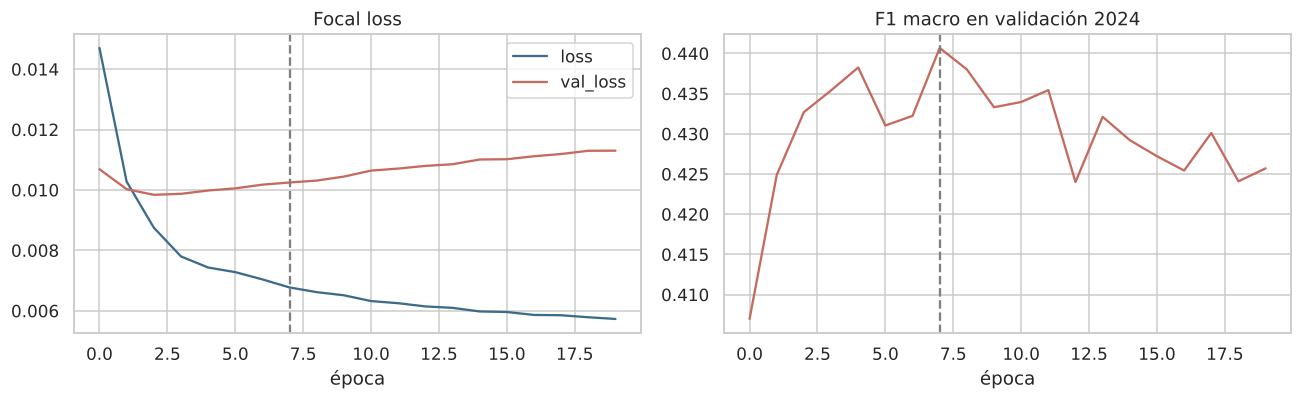

,Modelo,F1 macro valid,F1 macro test,Recall GRAVE,Recall MORTAL,Precision MORTAL,"pesos (G, M)"
0,Red Keras (1 semilla),0.446,0.463,0.303,0.2,0.178,"0.5, 0.2"


In [14]:
historia = red.fit(IN_tr, Y_tr, validation_data=(IN_va, Y_va), epochs=80, batch_size=512, verbose=0,
                   callbacks=[F1Validacion(lambda p: p, IN_va, y_va),
                              keras.callbacks.EarlyStopping(monitor="val_f1_macro", mode="max", patience=12,
                                                            restore_best_weights=True),
                              keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5,
                                                                min_lr=1e-5)])
h = pd.DataFrame(historia.history)
mejor_epoca = int(h["val_f1_macro"].idxmax()) + 1
print("épocas:", len(h), "| mejor época:", mejor_epoca, "| F1 macro valid:", round(h["val_f1_macro"].max(), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
h[["loss", "val_loss"]].plot(ax=axes[0], color=["#3E6B89", "#C46A5E"])
axes[0].set_title("Focal loss")
h["val_f1_macro"].plot(ax=axes[1], color="#C46A5E")
for ax in axes:
    ax.axvline(mejor_epoca - 1, ls="--", color="grey")
    ax.set_xlabel("época")
axes[1].set_title("F1 macro en validación 2024")
plt.tight_layout()
plt.savefig(f"{CARPETA_GRAFICOS}/curvas_entrenamiento.png", bbox_inches="tight")
plt.show()

registrar("Red Keras (1 semilla)", red.predict(IN_va, verbose=0), red.predict(IN_te, verbose=0))

### 4.3 Ensamble de 5 semillas
Con tan pocos mortales, dos redes con distinta semilla aciertan casos distintos. Promediar 5 reduce esa varianza, como hacía el ensamble del Notebook 2, pero con redes mejores.

In [15]:
def ajustar_red(constructor, y_fit, y_fit_val, a_probs, semilla, x_fit=IN_tr, y_val_int=y_va):
    m = constructor(semilla)
    m.fit(x_fit, y_fit, validation_data=(IN_va, y_fit_val), epochs=80, batch_size=512, verbose=0,
          callbacks=[F1Validacion(a_probs, IN_va, y_val_int),
                     keras.callbacks.EarlyStopping(monitor="val_f1_macro", mode="max", patience=12,
                                                   restore_best_weights=True),
                     keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)])
    return m


redes = [red] + [ajustar_red(red_multiclase, Y_tr, Y_va, lambda p: p, s) for s in [1, 2, 3, 4]]
prob_red_va = np.mean([m.predict(IN_va, verbose=0) for m in redes], axis=0)
prob_red_te = np.mean([m.predict(IN_te, verbose=0) for m in redes], axis=0)
registrar("Red Keras · ensamble 5", prob_red_va, prob_red_te)

,Modelo,F1 macro valid,F1 macro test,Recall GRAVE,Recall MORTAL,Precision MORTAL,"pesos (G, M)"
0,Red Keras · ensamble 5,0.457,0.438,0.173,0.333,0.111,"0.5, 0.3"


## 5. Enfoque ordinal en dos etapas
La gravedad tiene orden: LEVE < GRAVE < MORTAL. En lugar de tres clases independientes se encadenan dos preguntas binarias, cada una con una red como la anterior (salida sigmoide y focal loss binaria):

* **Etapa 1**, con todos los siniestros: $p_1 = P(\text{gravedad} \geq \text{GRAVE})$.
* **Etapa 2**, solo con graves y mortales: $p_2 = P(\text{MORTAL} \mid \text{gravedad} \geq \text{GRAVE})$.

Y se recomponen: $P(\text{LEVE}) = 1-p_1$, $P(\text{GRAVE}) = p_1(1-p_2)$, $P(\text{MORTAL}) = p_1 p_2$.

La ventaja: la etapa 2 aprende a separar GRAVE de MORTAL con un problema mucho menos desbalanceado (19 % de mortales en lugar de 1 %).

In [16]:
def red_binaria(semilla, alpha, gamma=2.0, lr=2e-3, wd=1e-4):
    keras.utils.set_random_seed(semilla)
    ins, x = cuerpo("binaria")
    out = layers.Dense(1, activation="sigmoid")(x)
    m = keras.Model(ins, out)
    m.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=wd),
              loss=keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=alpha, gamma=gamma))
    return m


class AUCValidacion(keras.callbacks.Callback):
    def __init__(self, x_val, y_val):
        super().__init__()
        self.x_val, self.y_val = x_val, y_val

    def on_epoch_end(self, epoch, logs=None):
        from sklearn.metrics import average_precision_score
        logs["val_pr_auc"] = average_precision_score(self.y_val, self.model.predict(self.x_val, batch_size=4096, verbose=0).ravel())


def filtrar(d, mascara):
    return {k: v_[mascara] for k, v_ in d.items()}


def ajustar_binaria(x, y, xv, yv, alpha, semilla):
    m = red_binaria(semilla, alpha)
    m.fit(x, y, validation_data=(xv, yv), epochs=80, batch_size=512 if len(y) > 10000 else 128, verbose=0,
          callbacks=[AUCValidacion(xv, yv),
                     keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=12,
                                                   restore_best_weights=True),
                     keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)])
    return m


b1_tr, b1_va = (y_tr >= 1).astype("float32"), (y_va >= 1).astype("float32")
s2_tr, s2_va = y_tr >= 1, y_va >= 1
b2_tr, b2_va = (y_tr[s2_tr] == 2).astype("float32"), (y_va[s2_va] == 2).astype("float32")

etapa1 = [ajustar_binaria(IN_tr, b1_tr, IN_va, b1_va, alpha=0.75, semilla=s) for s in range(5)]
etapa2 = [ajustar_binaria(filtrar(IN_tr, s2_tr), b2_tr, filtrar(IN_va, s2_va), b2_va, alpha=0.7, semilla=s)
          for s in range(5)]


def ordinal(x):
    p1 = np.mean([m.predict(x, verbose=0).ravel() for m in etapa1], axis=0)
    p2 = np.mean([m.predict(x, verbose=0).ravel() for m in etapa2], axis=0)
    return np.column_stack([1 - p1, p1 * (1 - p2), p1 * p2])


prob_ord_va, prob_ord_te = ordinal(IN_va), ordinal(IN_te)
registrar("Red ordinal 2 etapas · ensamble 5", prob_ord_va, prob_ord_te)

,Modelo,F1 macro valid,F1 macro test,Recall GRAVE,Recall MORTAL,Precision MORTAL,"pesos (G, M)"
0,Red ordinal 2 etapas · ensamble 5,0.457,0.435,0.137,0.2,0.167,"1.6, 1.6"


### 5.1 Lo mismo con LightGBM
Para saber si la ganancia viene de la descomposición ordinal o de la red, se aplica la misma idea con árboles.

In [17]:
def lgb_binario(x, y, xv, yv):
    m = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.02, num_leaves=15, min_child_samples=30,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
                           scale_pos_weight=(1 - y.mean()) / y.mean(), metric="average_precision",
                           random_state=SEMILLA, verbose=-1)
    m.fit(x, y, eval_set=[(xv, yv)], callbacks=[lgb.early_stopping(100, verbose=False)])
    return m


Xl_tr, Xl_va, Xl_te = X_lgb[es_train], X_lgb[es_valid], X_lgb[es_test]
lgb1 = lgb_binario(Xl_tr, b1_tr, Xl_va, b1_va)
lgb2 = lgb_binario(Xl_tr[s2_tr], b2_tr, Xl_va[s2_va], b2_va)


def ordinal_lgb(x):
    p1, p2 = lgb1.predict_proba(x)[:, 1], lgb2.predict_proba(x)[:, 1]
    return np.column_stack([1 - p1, p1 * (1 - p2), p1 * p2])


registrar("LightGBM ordinal 2 etapas", ordinal_lgb(Xl_va), ordinal_lgb(Xl_te))

/usr/local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/usr/local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,Modelo,F1 macro valid,F1 macro test,Recall GRAVE,Recall MORTAL,Precision MORTAL,"pesos (G, M)"
0,LightGBM ordinal 2 etapas,0.456,0.422,0.118,0.156,0.154,"0.5, 0.2"


### 5.2 Ensamble red + LightGBM
Las redes y los árboles se equivocan distinto. Se promedian las probabilidades del mejor esquema de cada familia.

In [18]:
registrar("Ensamble red ordinal + LightGBM",
          (prob_ord_va + lgbm.predict_proba(X_lgb[es_valid])) / 2,
          (prob_ord_te + lgbm.predict_proba(X_lgb[es_test])) / 2)

,Modelo,F1 macro valid,F1 macro test,Recall GRAVE,Recall MORTAL,Precision MORTAL,"pesos (G, M)"
0,Ensamble red ordinal + LightGBM,0.451,0.425,0.153,0.1,0.164,"1.1, 0.6"


## 6. Resultados en test 2025

In [19]:
tabla = pd.DataFrame(resultados).set_index("Modelo")
tabla.round(3).style.background_gradient(subset=["F1 macro test", "Recall MORTAL"], cmap="OrRd")

,F1 macro valid,F1 macro test,Recall GRAVE,Recall MORTAL,Precision MORTAL,"pesos (G, M)"
Modelo,,,,,,
RF · variables del Notebook 2,0.428000,0.400000,0.137000,0.056000,0.111000,"0.8, 0.2"
Random Forest,0.457000,0.438000,0.272000,0.089000,0.136000,"1.1, 0.5"
LightGBM,0.447000,0.434000,0.178000,0.167000,0.134000,"0.9, 0.6"
Red Keras (1 semilla),0.446000,0.463000,0.303000,0.200000,0.178000,"0.5, 0.2"
Red Keras · ensamble 5,0.457000,0.438000,0.173000,0.333000,0.111000,"0.5, 0.3"
Red ordinal 2 etapas · ensamble 5,0.457000,0.435000,0.137000,0.200000,0.167000,"1.6, 1.6"
LightGBM ordinal 2 etapas,0.456000,0.422000,0.118000,0.156000,0.154000,"0.5, 0.2"
Ensamble red ordinal + LightGBM,0.451000,0.425000,0.153000,0.100000,0.164000,"1.1, 0.6"


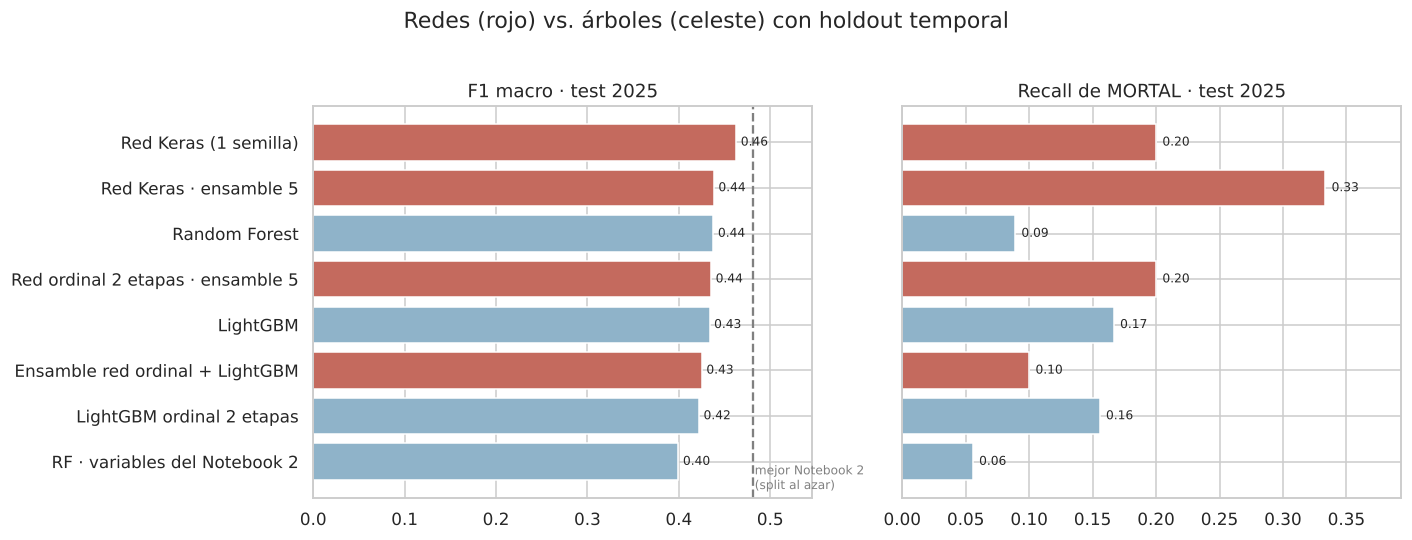

In [20]:
t = tabla.sort_values("F1 macro test")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
colores = ["#C46A5E" if "Red" in n or "red" in n else "#8FB3C9" for n in t.index]
axes[0].barh(t.index, t["F1 macro test"], color=colores)
axes[0].axvline(0.481, ls="--", color="grey")
axes[0].text(0.483, -0.6, "mejor Notebook 2\n(split al azar)", fontsize=8, color="grey")
axes[0].set_title("F1 macro · test 2025")
axes[1].barh(t.index, t["Recall MORTAL"], color=colores)
axes[1].set_title("Recall de MORTAL · test 2025")
for ax, col in zip(axes, ["F1 macro test", "Recall MORTAL"]):
    for i, v_ in enumerate(t[col]):
        ax.text(v_ + 0.005, i, f"{v_:.2f}", va="center", fontsize=8)
    ax.set_xlim(0, max(t[col]) * 1.18)
plt.suptitle("Redes (rojo) vs. árboles (celeste) con holdout temporal", y=1.02)
plt.tight_layout()
plt.savefig(f"{CARPETA_GRAFICOS}/comparacion_modelos.png", bbox_inches="tight")
plt.show()

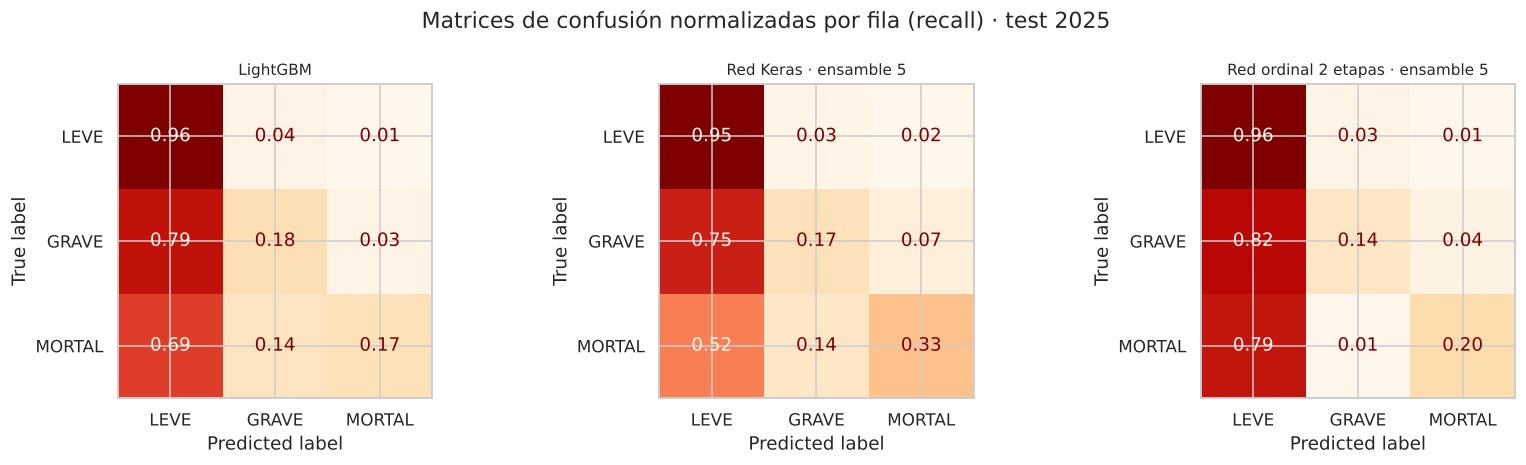

Mejor modelo en test: Red Keras (1 semilla)
              precision    recall  f1-score   support

        LEVE      0.953     0.931     0.942     10975
       GRAVE      0.224     0.303     0.258       687
      MORTAL      0.178     0.200     0.188        90

    accuracy                          0.889     11752
   macro avg      0.452     0.478     0.463     11752
weighted avg      0.905     0.889     0.896     11752



In [21]:
mostrar = ["LightGBM", "Red Keras · ensamble 5", "Red ordinal 2 etapas · ensamble 5"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, nombre in zip(axes, mostrar):
    ConfusionMatrixDisplay.from_predictions(y_te, predicciones[nombre], display_labels=CLASES,
                                            normalize="true", values_format=".2f", cmap="OrRd",
                                            ax=ax, colorbar=False)
    ax.set_title(nombre, fontsize=10)
plt.suptitle("Matrices de confusión normalizadas por fila (recall) · test 2025")
plt.tight_layout()
plt.savefig(f"{CARPETA_GRAFICOS}/matrices_confusion.png", bbox_inches="tight")
plt.show()

mejor = tabla["F1 macro test"].idxmax()
print("Mejor modelo en test:", mejor)
print(classification_report(y_te, predicciones[mejor], target_names=CLASES, digits=3))

## 7. Qué aprendió la red
### 7.1 Embeddings de `participantes_siniestro`
Cada combinación de participantes (MOTO-AUTO, PEATON-COLECTIVO...) es un vector de 12 dimensiones aprendido. Proyectado a 2D con PCA y coloreado por la tasa real de graves y mortales en train, se ve si la red ordenó las categorías por riesgo sin que nadie se lo dijera.

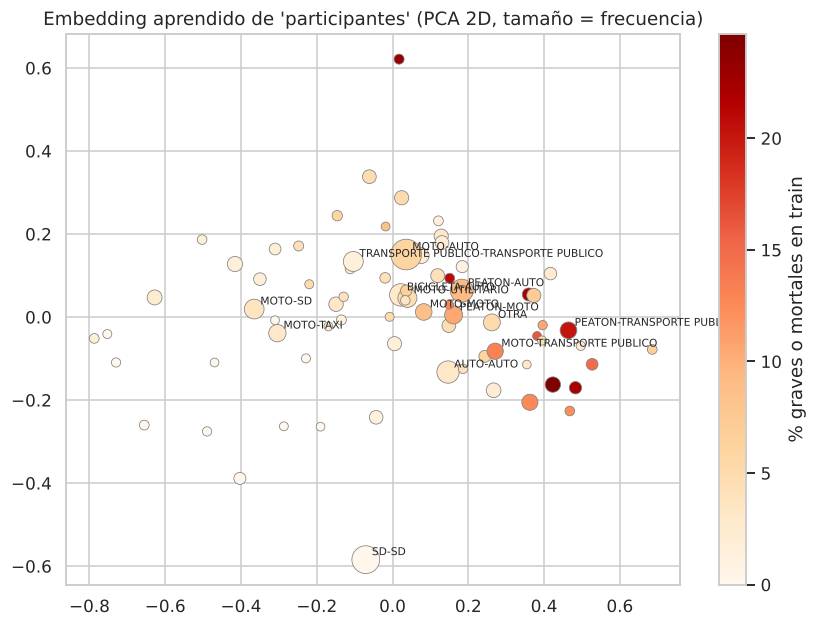

In [22]:
pesos = red.get_layer("emb_participantes_siniestro").get_weights()[0]
coords = PCA(2, random_state=SEMILLA).fit_transform(pesos)
tasa_cat = (datos[es_train].groupby("participantes_siniestro_id")["grave_o_mortal"].mean()
            .reindex(range(len(vocab["participantes_siniestro"]))))
n_cat = datos[es_train]["participantes_siniestro_id"].value_counts().reindex(range(len(pesos))).fillna(0)

fig, ax = plt.subplots(figsize=(9, 6.5))
sc = ax.scatter(coords[:, 0], coords[:, 1], c=tasa_cat * 100, s=np.sqrt(n_cat) * 4 + 10, cmap="OrRd",
                edgecolor="grey", linewidth=0.5)
for i in n_cat.sort_values().index[-14:]:
    ax.annotate(vocab["participantes_siniestro"][i], coords[i], fontsize=7, xytext=(4, 3), textcoords="offset points")
plt.colorbar(sc, label="% graves o mortales en train")
ax.set_title("Embedding aprendido de 'participantes' (PCA 2D, tamaño = frecuencia)")
plt.savefig(f"{CARPETA_GRAFICOS}/embedding_participantes.png", bbox_inches="tight")
plt.show()

### 7.2 Importancia por permutación (red ordinal)
Caída del F1 macro en test al desordenar cada variable (las numéricas, una a una; las categóricas, su columna de ids).

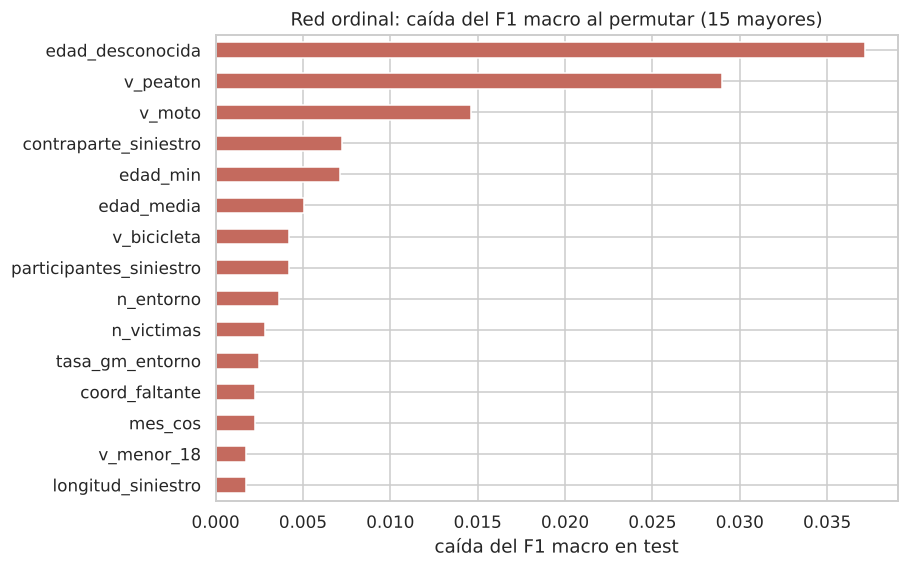

In [23]:
w_ord = ajustar_pesos(prob_ord_va, y_va)
base_f1 = f1_score(y_te, (prob_ord_te * w_ord).argmax(1), average="macro")
rng = np.random.default_rng(SEMILLA)
caidas = {}
for nombre in CAT_IDS + NUMERICAS:
    vals = []
    for _ in range(3):
        x = {k: v_.copy() for k, v_ in IN_te.items()}
        if nombre in CAT_IDS:
            x[nombre] = rng.permutation(x[nombre])
        else:
            j = NUMERICAS.index(nombre)
            x["num"][:, j] = rng.permutation(x["num"][:, j])
        vals.append(base_f1 - f1_score(y_te, (ordinal(x) * w_ord).argmax(1), average="macro"))
    caidas[nombre.replace("_id", "")] = np.mean(vals)

imp = pd.Series(caidas).sort_values().tail(15)
imp.plot(kind="barh", color="#C46A5E", figsize=(8, 5.5))
plt.title("Red ordinal: caída del F1 macro al permutar (15 mayores)")
plt.xlabel("caída del F1 macro en test")
plt.savefig(f"{CARPETA_GRAFICOS}/importancia_red.png", bbox_inches="tight")
plt.show()

## 8. Conclusiones

**Resultados en test 2025** (entrenado con 2019-2023, umbrales elegidos en 2024; 11.752 siniestros, 90 mortales):

| Modelo | F1 macro | Recall GRAVE | Recall MORTAL | Precision MORTAL |
|---|---|---|---|---|
| RF · variables del Notebook 2 | 0,400 | 0,14 | 0,06 | 0,11 |
| Random Forest (variables nuevas) | 0,438 | 0,27 | 0,09 | 0,14 |
| LightGBM | 0,434 | 0,18 | 0,17 | 0,13 |
| **Red Keras (1 semilla)** | **0,463** | **0,30** | 0,20 | **0,18** |
| Red Keras · ensamble 5 | 0,438 | 0,17 | **0,33** | 0,11 |
| Red ordinal 2 etapas · ensamble 5 | 0,435 | 0,14 | 0,20 | 0,17 |
| LightGBM ordinal 2 etapas | 0,422 | 0,12 | 0,16 | 0,15 |

**1. El split temporal es más exigente que el aleatorio.** El mismo Random Forest del Notebook 2 cae de 0,48 (split al azar) a **0,40** cuando se lo evalúa en 2025. El 0,48 era optimista: 2025 tiene menos mortales (0,8 %) y más graves (5,8 %) que el promedio. Toda comparación con el Notebook 2 tiene que hacerse contra esta fila, no contra el 0,48.

**2. Las variables nuevas valen más que el cambio de modelo.** Con las mismas variables del Notebook 2 el RF da 0,40; con las nuevas (agregados de víctimas, entorno H3, tiempo cíclico) sube a 0,44. Los árboles y las redes quedan en un rango de 0,43 a 0,46.

**3. La red en Keras es el mejor modelo en F1 macro y en recall de MORTAL.** La red simple supera a LightGBM y a RF en F1 macro (0,463) y el ensamble de 5 redes detecta **un tercio de los mortales** (0,33), contra 0,09 a 0,17 de los árboles. Lo que cambió respecto del `MLPClassifier`: embeddings en lugar de dummies, focal loss con alfa por clase, BatchNorm y early stopping guiado por el F1 macro.

**4. El enfoque ordinal no ganó.** Separar el problema en dos etapas dio 0,435 con redes y 0,422 con LightGBM: la etapa 2 aprende con solo unos 2.300 casos (graves y mortales de train) y el error de la etapa 1 se propaga. Queda como alternativa interpretable, no como mejora.

**5. Cautelas.**
* Con 90 mortales en test, una diferencia de 0,02 en F1 macro está dentro del ruido (cambia con la semilla, como muestra la diferencia entre la red simple y el ensamble). La lectura robusta es «las redes empatan o superan a los árboles, y detectan más mortales».
* La variable más importante para la red es `edad_desconocida`. Es en parte un **artefacto de registro**: la edad falta en el 33 % de las víctimas leves y casi nunca en las graves o mortales. Lo mismo ocurre con el sexo. Se dejó porque está disponible al momento del hecho, pero un modelo para producción debería revisarla con la fuente de datos.
* Se excluyeron por fuga el prefijo del id (HC/LC), `rol_victima`, la gravedad de la víctima y la fecha de fallecimiento.

**Próximos pasos:** búsqueda de hiperparámetros de la red con KerasTuner u Optuna validando por año, calibración de probabilidades y un análisis de errores sobre los mortales no detectados.

In [24]:
tabla.round(3).to_csv("resultados_modelos.csv")
tabla[["F1 macro test", "Recall MORTAL", "Recall GRAVE", "Precision MORTAL"]].round(3)

,F1 macro test,Recall MORTAL,Recall GRAVE,Precision MORTAL
Modelo,,,,
RF · variables del Notebook 2,0.400,0.056,0.137,0.111
Random Forest,0.438,0.089,0.272,0.136
LightGBM,0.434,0.167,0.178,0.134
Red Keras (1 semilla),0.463,0.200,0.303,0.178
Red Keras · ensamble 5,0.438,0.333,0.173,0.111
Red ordinal 2 etapas · ensamble 5,0.435,0.200,0.137,0.167
LightGBM ordinal 2 etapas,0.422,0.156,0.118,0.154
Ensamble red ordinal + LightGBM,0.425,0.100,0.153,0.164
